# E-Commerce Business Performance & Customer Analytics

## Python Exploratory Data Analysis

**Dataset:** Olist Brazilian E-Commerce Dataset

**Tools:** Python, Pandas, NumPy, Matplotlib

### Business Objectives
1. Analyse sales performance and revenue trends.
2. Understand customer purchasing and retention behaviour.
3. Evaluate delivery performance.
4. Investigate customer satisfaction and review ratings.
5. Generate actionable business insights.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define dataset folder
data_path = Path("../Raw_Data")

# Load datasets
orders = pd.read_csv(data_path / "olist_orders_dataset.csv")

customers = pd.read_csv(data_path / "olist_customers_dataset.csv")

order_items = pd.read_csv(data_path / "olist_order_items_dataset.csv")

products = pd.read_csv(data_path / "olist_products_dataset.csv")

reviews = pd.read_csv(data_path / "olist_order_reviews_dataset.csv")

category_translation = pd.read_csv(
    data_path / "product_category_name_translation.csv"
)

# Display dataset sizes
datasets = {
    "Orders": orders,
    "Customers": customers,
    "Order Items": order_items,
    "Products": products,
    "Reviews": reviews,
    "Category Translation": category_translation
}

for name, df in datasets.items():
    print(f"{name}: {len(df):,} rows")

Orders: 99,441 rows
Customers: 99,441 rows
Order Items: 112,650 rows
Products: 32,951 rows
Reviews: 99,224 rows
Category Translation: 71 rows


## 1. Data Quality Assessment

### 1.1 Missing Value Analysis

Identify missing values across the datasets to assess data completeness.

In [3]:
# Check missing values across datasets

for name, df in datasets.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    print(f"\n{name} - Missing Values")

    if missing.empty:
        print("No missing values")
    else:
        print(missing.to_string())


Orders - Missing Values
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

Customers - Missing Values
No missing values

Order Items - Missing Values
No missing values

Products - Missing Values
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2

Reviews - Missing Values
review_comment_title      87656
review_comment_message    58247

Category Translation - Missing Values
No missing values


In [4]:
# Check duplicate rows

print("Duplicate Row Analysis\n")

for name, df in datasets.items():
    duplicates = df.duplicated().sum()
    print(f"{name}: {duplicates:,} duplicate rows")

Duplicate Row Analysis

Orders: 0 duplicate rows
Customers: 0 duplicate rows
Order Items: 0 duplicate rows
Products: 0 duplicate rows
Reviews: 0 duplicate rows
Category Translation: 0 duplicate rows


### 1.2 Order Date and Status Validation

Validate the transaction period and examine the distribution of order statuses.

In [5]:
# Convert purchase timestamp to datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

# Check transaction date range
print("Earliest Order:",
      orders["order_purchase_timestamp"].min())

print("Latest Order:",
      orders["order_purchase_timestamp"].max())

# Check order status distribution
print("\nOrder Status Distribution:")

print(orders["order_status"].value_counts())

# Validate unique order IDs
print("\nUnique Orders:",
      orders["order_id"].nunique())

print("Missing Order IDs:",
      orders["order_id"].isnull().sum())

Earliest Order: 2016-09-04 21:15:19
Latest Order: 2018-10-17 17:30:18

Order Status Distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Unique Orders: 99441
Missing Order IDs: 0


## 2. Sales Performance Analysis

### 2.1 Key Sales Metrics

Calculate total sales, total orders, average order value
and delivery rate.

In [6]:
# Calculate sales KPIs

total_orders = orders["order_id"].nunique()

total_sales = order_items["price"].sum()

orders_with_items = order_items["order_id"].nunique()

average_order_value = total_sales / orders_with_items

delivered_orders = (
    orders["order_status"] == "delivered"
).sum()

delivery_rate = delivered_orders / total_orders * 100

print(f"Total Orders: {total_orders:,}")
print(f"Total Sales: R${total_sales:,.2f}")
print(f"Average Order Value: R${average_order_value:,.2f}")
print(f"Delivered Orders: {delivered_orders:,}")
print(f"Delivery Rate: {delivery_rate:.2f}%")

Total Orders: 99,441
Total Sales: R$13,591,643.70
Average Order Value: R$137.75
Delivered Orders: 96,478
Delivery Rate: 97.02%


In [7]:
# Merge order items with purchase dates
sales_data = order_items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

# Create monthly period
sales_data["year_month"] = (
    sales_data["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Calculate monthly sales
monthly_sales = (
    sales_data.groupby("year_month")["price"]
    .sum()
    .reset_index(name="total_sales")
    .sort_values("year_month")
)

print(monthly_sales.to_string(index=False))

year_month  total_sales
   2016-09       267.36
   2016-10    49,507.66
   2016-12        10.90
   2017-01   120,312.87
   2017-02   247,303.02
   2017-03   374,344.30
   2017-04   359,927.23
   2017-05   506,071.14
   2017-06   433,038.60
   2017-07   498,031.48
   2017-08   573,971.68
   2017-09   624,401.69
   2017-10   664,219.43
   2017-11 1,010,271.37
   2017-12   743,914.17
   2018-01   950,030.36
   2018-02   844,178.71
   2018-03   983,213.44
   2018-04   996,647.75
   2018-05   996,517.68
   2018-06   865,124.31
   2018-07   895,507.22
   2018-08   854,686.33
   2018-09       145.00


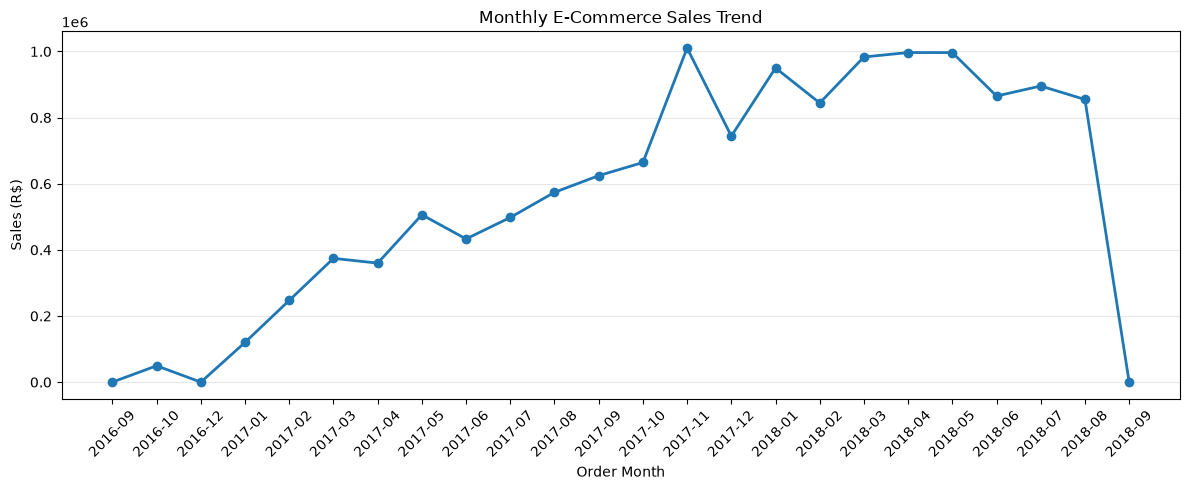

In [8]:
# Monthly sales trend visualization

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["year_month"].astype(str),
    monthly_sales["total_sales"],
    marker="o",
    linewidth=2
)

plt.title("Monthly E-Commerce Sales Trend")
plt.xlabel("Order Month")
plt.ylabel("Sales (R$)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Customer Analytics & Retention

### 3.1 Customer Purchasing Behaviour

Analyse unique customers, repeat purchases and one-time
customers using customer_unique_id.

In [9]:
# Merge orders with customer information
customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Count orders per unique customer
customer_order_counts = (
    customer_orders.groupby("customer_unique_id")["order_id"]
    .nunique()
)

# Calculate customer KPIs
unique_customers = customer_order_counts.size

repeat_customers = (customer_order_counts > 1).sum()

one_time_customers = (customer_order_counts == 1).sum()

repeat_customer_rate = (
    repeat_customers / unique_customers * 100
)

print(f"Unique Customers: {unique_customers:,}")
print(f"Repeat Customers: {repeat_customers:,}")
print(f"One-Time Customers: {one_time_customers:,}")
print(f"Repeat Customer Rate: {repeat_customer_rate:.2f}%")

Unique Customers: 96,096
Repeat Customers: 2,997
One-Time Customers: 93,099
Repeat Customer Rate: 3.12%


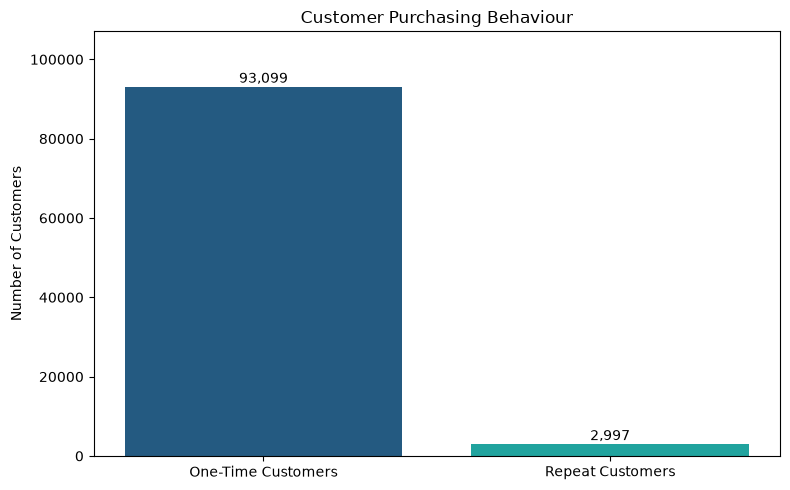

In [10]:
# Customer purchasing behaviour chart

customer_types = ["One-Time Customers", "Repeat Customers"]
customer_counts = [one_time_customers, repeat_customers]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    customer_types,
    customer_counts,
    color=["#245A81", "#20A39E"]
)

plt.title("Customer Purchasing Behaviour")
plt.ylabel("Number of Customers")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1000,
        f"{int(bar.get_height()):,}",
        ha="center"
    )

plt.ylim(0, max(customer_counts) * 1.15)
plt.tight_layout()

plt.savefig(
    "customer_repeat_purchase.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.2 Business Insights

**Key Finding:**
Approximately 3.12% of customers placed more than one order
during the observed dataset period.

**Business Implication:**
The relatively low repeat purchase rate suggests an opportunity
to investigate customer engagement and repeat purchasing.

**Recommendations:**
- Analyse repeat purchasing by product category.
- Investigate customer satisfaction among one-time buyers.
- Explore targeted retention and re-engagement campaigns.
- Monitor repeat purchase rate over time.

**Limitation:**
The dataset covers a historical observation period.
Customers may have purchased outside this period,
so the metric should not be interpreted as lifetime retention.

## 4. Delivery Performance Analysis

### 4.1 Delivery Time and On-Time Performance

Analyse delivery duration and evaluate whether orders
were delivered before or after their estimated delivery date.

In [11]:
# Convert delivery timestamps to datetime

date_columns = [
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(
        orders[col],
        errors="coerce"
    )

# Filter delivered orders
delivered = orders[
    orders["order_status"] == "delivered"
].copy()

# Keep orders with valid delivery dates
delivered = delivered.dropna(
    subset=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

# Calculate delivery days using calendar-day difference
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"].dt.normalize()
    - delivered["order_purchase_timestamp"].dt.normalize()
).dt.days

average_delivery_days = delivered["delivery_days"].mean()

print(f"Valid Delivered Orders: {len(delivered):,}")
print(f"Average Delivery Days: {average_delivery_days:.2f}")

Valid Delivered Orders: 96,470
Average Delivery Days: 12.50


In [12]:
# Classify delivery performance

delivered["delivery_performance"] = np.where(
    delivered["order_delivered_customer_date"].dt.normalize()
    <= delivered["order_estimated_delivery_date"].dt.normalize(),
    "On Time or Early",
    "Delivered Late"
)

delivery_summary = (
    delivered["delivery_performance"]
    .value_counts()
    .reindex(["On Time or Early", "Delivered Late"])
)

on_time_orders = delivery_summary["On Time or Early"]

late_orders = delivery_summary["Delivered Late"]

on_time_rate = on_time_orders / len(delivered) * 100

print("Delivery Performance Summary")
print(delivery_summary)

print(f"\nOn-Time Delivery Rate: {on_time_rate:.2f}%")
print(f"Late Delivery Rate: {100 - on_time_rate:.2f}%")

Delivery Performance Summary
delivery_performance
On Time or Early    89936
Delivered Late       6534
Name: count, dtype: int64

On-Time Delivery Rate: 93.23%
Late Delivery Rate: 6.77%


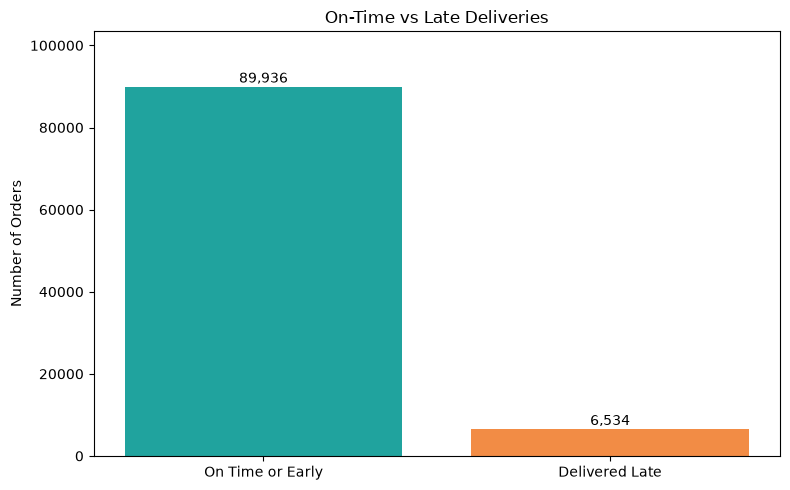

In [13]:
# Delivery performance visualization

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    delivery_summary.index,
    delivery_summary.values,
    color=["#20A39E", "#F28C45"]
)

ax.set_title("On-Time vs Late Deliveries")
ax.set_ylabel("Number of Orders")

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1000,
        f"{int(bar.get_height()):,}",
        ha="center"
    )

ax.set_ylim(0, delivery_summary.max() * 1.15)

plt.tight_layout()

plt.savefig(
    "monthly_delivery_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.2 Business Insights

**Key Finding:**
Approximately 93.23% of eligible delivered orders arrived
on or before their estimated delivery dates.

**Business Implication:**
Although most deliveries were on time, late deliveries
represent an opportunity to investigate operational
inefficiencies and customer experience.

**Recommendations:**
- Monitor delivery delays across different periods.
- Investigate factors associated with late deliveries.
- Analyse the relationship between delivery performance
  and customer review ratings.
- Track on-time delivery rate as an operational KPI.

**Limitation:**
Only delivered orders with valid purchase, actual delivery
and estimated delivery dates are included.

## 5. Customer Satisfaction Analysis

### 5.1 Customer Review Distribution

Analyse customer review scores to understand
overall customer satisfaction.

In [14]:
# Customer review distribution

review_distribution = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
)

average_review_score = reviews["review_score"].mean()

low_rating_reviews = (
    reviews["review_score"] <= 2
).sum()

low_rating_review_rate = (
    low_rating_reviews / len(reviews) * 100
)

print("Customer Review Distribution:")
print(review_distribution)

print(f"\nAverage Review Score: {average_review_score:.2f}")
print(f"Low Rating Reviews: {low_rating_reviews:,}")
print(f"Low Rating Review Rate: {low_rating_review_rate:.2f}%")

Customer Review Distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Average Review Score: 4.09
Low Rating Reviews: 14,575
Low Rating Review Rate: 14.69%


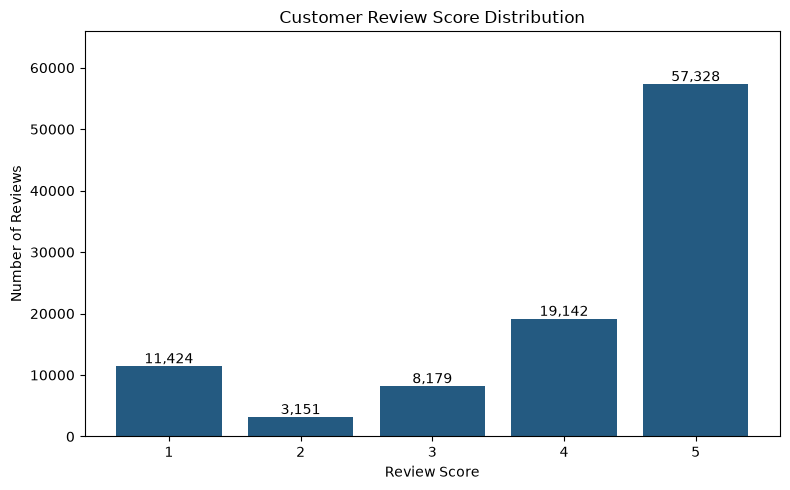

In [15]:
# Customer review distribution chart

plt.figure(figsize=(8, 5))

bars = plt.bar(
    review_distribution.index.astype(str),
    review_distribution.values,
    color="#245A81"
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 500,
        f"{int(bar.get_height()):,}",
        ha="center"
    )

plt.ylim(0, review_distribution.max() * 1.15)
plt.tight_layout()

plt.savefig(
    "customer_review_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.2 Delivery Performance vs Customer Satisfaction

Investigate the association between delivery timeliness,
average customer ratings and low-rating frequency.

Multiple reviews belonging to the same order are
aggregated to one order-level rating before analysis.

In [16]:
# Aggregate reviews to one row per order

order_reviews = (
    reviews.groupby("order_id", as_index=False)
    .agg(
        average_order_rating=("review_score", "mean")
    )
)

# Merge delivery performance with reviews
delivery_reviews = delivered[
    ["order_id", "delivery_performance"]
].merge(
    order_reviews,
    on="order_id",
    how="inner",
    validate="one_to_one"
)

# Calculate customer satisfaction by delivery performance
satisfaction_summary = (
    delivery_reviews
    .groupby("delivery_performance")
    .agg(
        total_orders=("order_id", "nunique"),
        average_rating=("average_order_rating", "mean"),
        low_rating_orders=(
            "average_order_rating",
            lambda x: (x <= 2).sum()
        )
    )
)

satisfaction_summary["low_rating_rate"] = (
    satisfaction_summary["low_rating_orders"]
    / satisfaction_summary["total_orders"] * 100
)

print(satisfaction_summary.round(2).to_string())

                      total_orders  average_rating  low_rating_orders  low_rating_rate
delivery_performance                                                                  
Delivered Late                6381            2.27               3979            62.36
On Time or Early             89443            4.29               8257             9.23


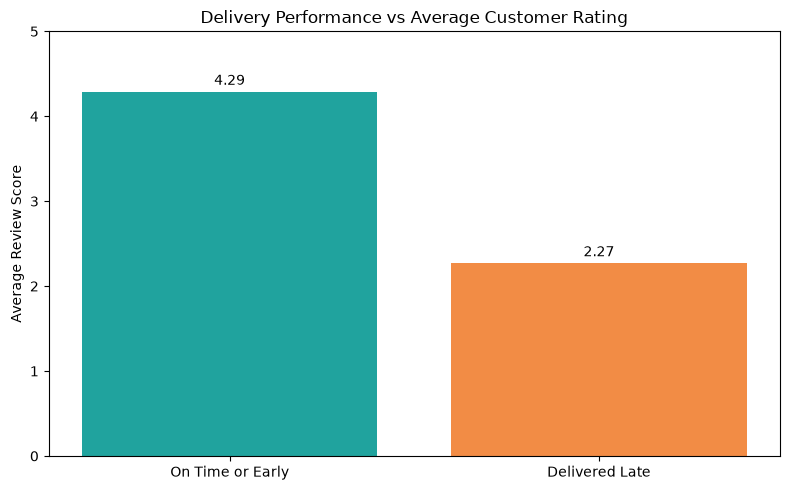

In [17]:
# Compare average review scores by delivery performance

rating_comparison = satisfaction_summary.reindex(
    ["On Time or Early", "Delivered Late"]
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    rating_comparison.index,
    rating_comparison["average_rating"],
    color=["#20A39E", "#F28C45"]
)

plt.title("Delivery Performance vs Average Customer Rating")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{bar.get_height():.2f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "delivery_vs_low_ratings.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.3 Business Insights

**Key Finding:**

Late deliveries are associated with substantially
lower customer review ratings.

**Business Implications:**

Delivery reliability appears to be an important
factor associated with customer satisfaction.

**Recommendations:**

- Monitor late deliveries and customer ratings together.
- Investigate operational causes of delivery delays.
- Prioritise customer support for delayed orders.
- Analyse delivery performance by seller and region.
- Track low-rating frequency among late deliveries.

**Limitations:**

The analysis measures association, not causation.
Only delivered orders with valid delivery dates and
available customer reviews are included.

## 6. Final KPI Validation

Consolidated business metrics calculated using Python.

These results are cross-checked against the SQL analysis
and Power BI dashboard to ensure consistency.

# Final KPI Summary

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Orders",
        "Total Sales (R$)",
        "Average Order Value (R$)",
        "Delivered Orders",
        "Delivery Rate (%)",
        "Unique Customers",
        "Repeat Customers",
        "Repeat Customer Rate (%)",
        "Average Delivery Days",
        "On-Time Delivery Rate (%)",
        "Average Review Score",
        "Low Rating Reviews"
    ],
    "Value": [
        total_orders,
        round(total_sales, 2),
        round(average_order_value, 2),
        delivered_orders,
        round(delivery_rate, 2),
        unique_customers,
        repeat_customers,
        round(repeat_customer_rate, 2),
        round(average_delivery_days, 2),
        round(on_time_rate, 2),
        round(average_review_score, 2),
        low_rating_reviews
    ]
})

display(kpi_summary)

# Save KPI summary
kpi_summary.to_csv("python_kpi_summary.csv", index=False)

print("Final KPI summary saved successfully!")

In [18]:
## 7. Conclusion & Business Recommendations

### Key Findings

1. Sales performance can be monitored through order volume,
   average order value and monthly revenue trends.

2. Approximately 3.12% of customers made repeat purchases
   during the observed period.

3. Approximately 93.23% of eligible delivered orders
   arrived on time or early.

4. Late deliveries were associated with substantially
   lower customer satisfaction ratings.

### Business Recommendations

- Investigate opportunities to improve repeat purchasing.
- Monitor delivery delays and identify operational bottlenecks.
- Analyse customer complaints and low-rated orders.
- Prioritise customer experience improvements for late deliveries.
- Use interactive dashboards for ongoing KPI monitoring.

### Analytical Limitations

- The dataset represents historical transactions.
- Sales exclude freight and do not measure profitability.
- Partial months may affect time-series comparisons.
- Observed associations do not establish causation.

### Tools Demonstrated

Python | Pandas | NumPy | Matplotlib |
Data Cleaning | Exploratory Data Analysis |
Data Aggregation | Data Visualisation |
Business KPI Analysis

SyntaxError: invalid syntax (3874918572.py, line 5)

## 7. Conclusion & Business Recommendations

### Key Findings

1. Sales performance can be monitored through order volume,
   average order value and monthly revenue trends.

2. Approximately 3.12% of customers made repeat purchases
   during the observed period.

3. Approximately 93.23% of eligible delivered orders
   arrived on time or early.

4. Late deliveries were associated with substantially
   lower customer satisfaction ratings.

### Business Recommendations

- Investigate opportunities to improve repeat purchasing.
- Monitor delivery delays and identify operational bottlenecks.
- Analyse customer complaints and low-rated orders.
- Prioritise customer experience improvements for late deliveries.
- Use interactive dashboards for ongoing KPI monitoring.

### Analytical Limitations

- The dataset represents historical transactions.
- Sales exclude freight and do not measure profitability.
- Partial months may affect time-series comparisons.
- Observed associations do not establish causation.

### Tools Demonstrated

Python | Pandas | NumPy | Matplotlib |
Data Cleaning | Exploratory Data Analysis |
Data Aggregation | Data Visualisation |
Business KPI Analysis